In [26]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3-flash-preview")

## Routing

Routing is how a workflow chooses which step should run next. A routing function looks at the current state and sends the workflow down the path that fits. In this example, the decider identifies the post category (Instagram, LinkedIn, or Twitter), and the graph routes to the matching node to write the post. This is useful when a workflow needs to respond differently depending on its input or on results from an earlier step.

#### LLM structured output schema

In [27]:
from pydantic import BaseModel, Field
from typing import Literal

class llm_schema(BaseModel):
    category: Literal['insta', 'twitter', 'linkedin'] = Field(..., description="Category of the post to generate")
    topic: str = Field(..., description="Topic of the post to generate")

In [28]:
llm_with_schema = llm.with_structured_output(llm_schema)

#### Graph schema

In [29]:
from typing import TypedDict

class graph_schema(TypedDict):
    input: str
    topic: str
    category: str
    post: str

#### Create node functions

In [30]:
def decider(state: graph_schema) -> graph_schema:

    user_input = state['input']

    response = llm_with_schema.invoke(user_input)
    category = response.category
    topic = response.topic

    state['category'] = category
    state['topic'] = topic

    return state

def create_post_insta(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write an Instagram post about {topic}. Keep the tone casual and engaging.").content
    state['post'] = post

    return {"post": post}

def create_post_linkedin(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write a LinkedIn post about {topic}. Keep the tone professional and informative.").content
    state['post'] = post

    return {"post": post}

def create_post_twitter(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write a Twitter post about {topic}. Keep the tone quick and to the point.").content
    state['post'] = post

    return {"post": post}

#### Create the conditional function

In [31]:
def conditional_func(state: graph_schema) -> str:

    category = state['category']

    if category == 'insta':
        return "create_post_insta"
    elif category == 'linkedin':
        return "create_post_linkedin"
    if category == 'twitter':
        return "create_post_twitter"
    else:
        raise ValueError(f"Unknown category: {state['category']}")

#### Create the graph

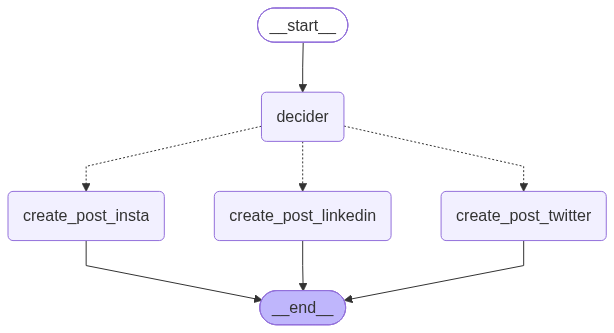

In [32]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("decider", decider)
graph.add_node("create_post_insta", create_post_insta)
graph.add_node("create_post_linkedin", create_post_linkedin)
graph.add_node("create_post_twitter", create_post_twitter)

graph.add_edge(START, "decider")
graph.add_conditional_edges("decider", conditional_func, {
    "create_post_insta": "create_post_insta",
    "create_post_linkedin": "create_post_linkedin",
    "create_post_twitter": "create_post_twitter"
})
graph.add_edge("create_post_insta", END)
graph.add_edge("create_post_linkedin", END)
graph.add_edge("create_post_twitter", END)

route_graph = graph.compile()

from IPython.display import Image

Image(route_graph.get_graph().draw_mermaid_png())

In [33]:
route_graph.invoke({
    "input": "I want to generate a post to linkedin about LangGraph.",
    "topic": "",
    "category": "",
    "post": ""
})

{'input': 'I want to generate a post to linkedin about LangGraph.',
 'topic': 'LangGraph',
 'category': 'linkedin',
 'post': [{'type': 'text',
   'text': 'Here are three options for a LinkedIn post about LangGraph, ranging from a high-level strategic view to a more technical deep dive.\n\n### Option 1: Strategic & High-Level (Best for thought leadership)\n\n**Headline: Moving beyond linear AI: Why LangGraph is a game-changer for Agentic Workflows.**\n\nThe transition from simple LLM prompts to complex AI agents is officially underway. \n\nWhile basic RAG (Retrieval-Augmented Generation) and linear chains have taken us far, real-world business processes are rarely a straight line. They are iterative, they require loops, and they often need human intervention.\n\nThis is where **LangGraph** comes in.\n\nDeveloped by the LangChain team, LangGraph allows developers to build stateful, multi-agent applications by representing workflows as graphs. Why does this matter?\n\n✅ **Cyclic Logic:** 